In [1]:
from pathlib import Path
import os
import sys
import zipfile
import tarfile
import shutil
import random
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

print("Python:", sys.version)

Python: 3.12.10 (tags/v3.12.10:0cc8128, Apr  8 2025, 12:21:36) [MSC v.1943 64 bit (AMD64)]


In [2]:
BASE_DIR = Path.cwd()

DATASET_DIR = BASE_DIR / "datasets"
RESULTS_DIR = BASE_DIR / "results"
MODELS_DIR = BASE_DIR / "models"

COCO_DIR = DATASET_DIR / "coco"
WIDER_DIR = DATASET_DIR / "widerface"
CELEBA_DIR = DATASET_DIR / "celeba"
LFW_DIR = DATASET_DIR / "lfw"

for folder in [
    DATASET_DIR,
    RESULTS_DIR,
    MODELS_DIR,
    COCO_DIR,
    WIDER_DIR,
    CELEBA_DIR,
    LFW_DIR
]:
    folder.mkdir(parents=True, exist_ok=True)

print("Project directory:")
print(BASE_DIR)

print("\nDatasets:")
for folder in [COCO_DIR, WIDER_DIR, CELEBA_DIR, LFW_DIR]:
    print(folder)

Project directory:
C:\Users\akars\Capstone\AI_Intruder_Capstone

Datasets:
C:\Users\akars\Capstone\AI_Intruder_Capstone\datasets\coco
C:\Users\akars\Capstone\AI_Intruder_Capstone\datasets\widerface
C:\Users\akars\Capstone\AI_Intruder_Capstone\datasets\celeba
C:\Users\akars\Capstone\AI_Intruder_Capstone\datasets\lfw


In [3]:
### !pip install -q scikit-learn matplotlib pandas pillow

In [4]:
from sklearn.datasets import fetch_lfw_people

lfw = fetch_lfw_people(
    min_faces_per_person=20,
    resize=0.5,
    color=True
)

print("Images:", lfw.images.shape)
print("Targets:", lfw.target.shape)
print("People:", len(lfw.target_names))

Images: (3023, 62, 47, 3)
Targets: (3023,)
People: 62


In [5]:

print("Number of identities:", len(lfw.target_names))

for i, name in enumerate(lfw.target_names[:20]):
    print(i, name)

Number of identities: 62
0 Alejandro Toledo
1 Alvaro Uribe
2 Amelie Mauresmo
3 Andre Agassi
4 Angelina Jolie
5 Ariel Sharon
6 Arnold Schwarzenegger
7 Atal Bihari Vajpayee
8 Bill Clinton
9 Carlos Menem
10 Colin Powell
11 David Beckham
12 Donald Rumsfeld
13 George Robertson
14 George W Bush
15 Gerhard Schroeder
16 Gloria Macapagal Arroyo
17 Gray Davis
18 Guillermo Coria
19 Hamid Karzai


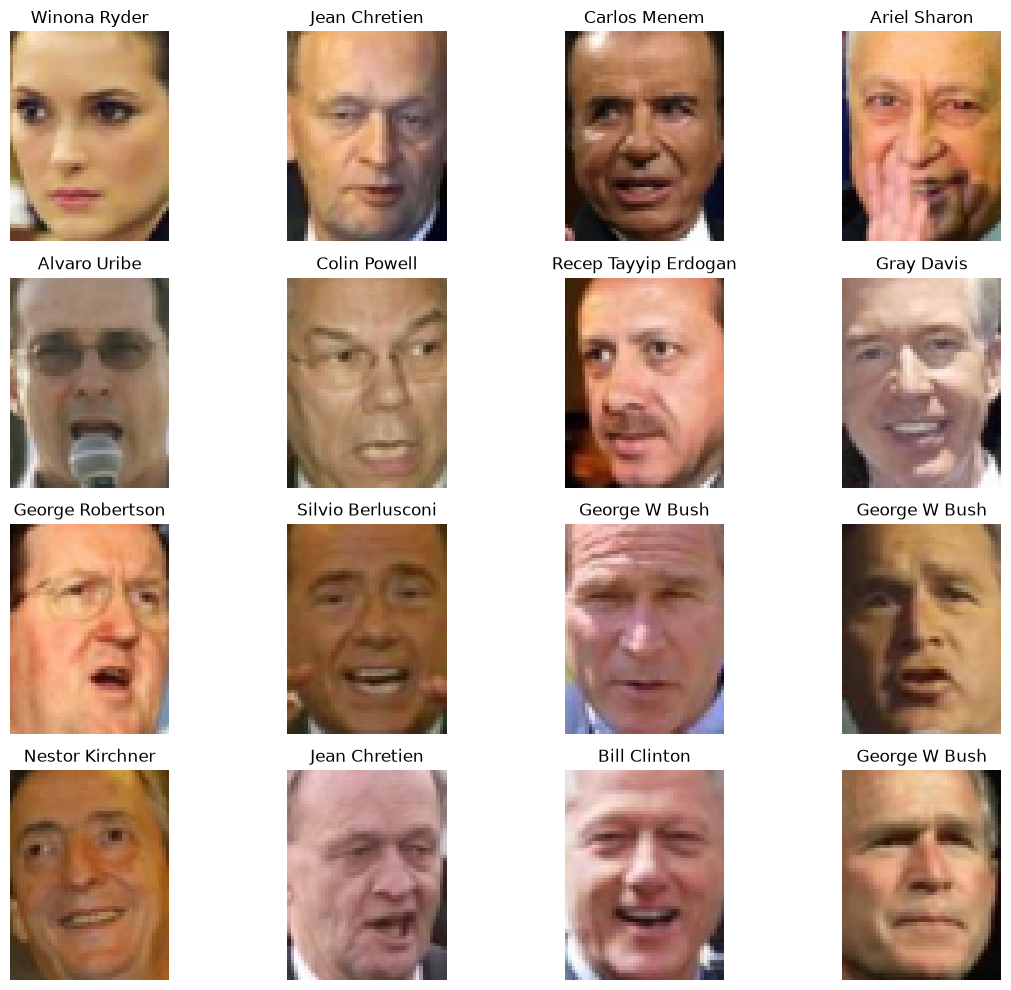

In [6]:
plt.figure(figsize=(12, 10))

for i in range(16):
    plt.subplot(4, 4, i + 1)

    plt.imshow(lfw.images[i])
    plt.title(lfw.target_names[lfw.target[i]])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [7]:
NUM_AUTHORIZED = 5

authorized_ids = list(range(NUM_AUTHORIZED))

authorized_names = [
    lfw.target_names[i]
    for i in authorized_ids
]

print("Authorized people:")
for name in authorized_names:
    print("-", name)

Authorized people:
- Alejandro Toledo
- Alvaro Uribe
- Amelie Mauresmo
- Andre Agassi
- Angelina Jolie


In [8]:
identity_images = {}

for person_id in range(len(lfw.target_names)):
    indices = np.where(lfw.target == person_id)[0]
    identity_images[person_id] = indices

for person_id in authorized_ids:
    print(
        lfw.target_names[person_id],
        "->",
        len(identity_images[person_id]),
        "images"
    )

Alejandro Toledo -> 39 images
Alvaro Uribe -> 35 images
Amelie Mauresmo -> 21 images
Andre Agassi -> 36 images
Angelina Jolie -> 20 images


In [9]:
random.seed(42)

enrollment_data = {}
test_data = {}

for person_id in authorized_ids:

    indices = list(identity_images[person_id])

    random.shuffle(indices)

    split = len(indices) // 2

    enrollment_data[person_id] = indices[:split]
    test_data[person_id] = indices[split:]

print("Enrollment/Test split:")
    
for person_id in authorized_ids:
    print(
        lfw.target_names[person_id],
        "Enrollment:",
        len(enrollment_data[person_id]),
        "Test:",
        len(test_data[person_id])
    )

Enrollment/Test split:
Alejandro Toledo Enrollment: 19 Test: 20
Alvaro Uribe Enrollment: 17 Test: 18
Amelie Mauresmo Enrollment: 10 Test: 11
Andre Agassi Enrollment: 18 Test: 18
Angelina Jolie Enrollment: 10 Test: 10


In [10]:

NUM_INTRUDERS = 10

all_ids = list(range(len(lfw.target_names)))

intruder_ids = [
    person_id
    for person_id in all_ids
    if person_id not in authorized_ids
][:NUM_INTRUDERS]

print("Intruder identities:")

for person_id in intruder_ids:
    print("-", lfw.target_names[person_id])

Intruder identities:
- Ariel Sharon
- Arnold Schwarzenegger
- Atal Bihari Vajpayee
- Bill Clinton
- Carlos Menem
- Colin Powell
- David Beckham
- Donald Rumsfeld
- George Robertson
- George W Bush


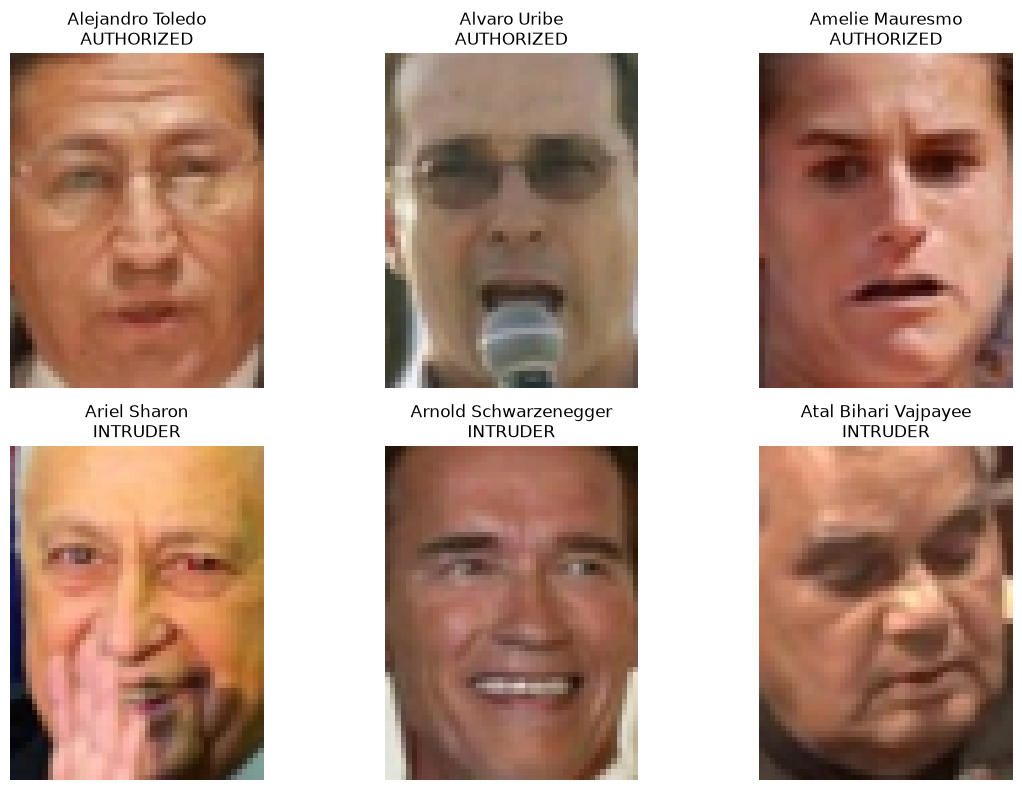

In [11]:
fig = plt.figure(figsize=(12, 8))

selected_indices = []

for person_id in authorized_ids[:3]:
    selected_indices.append(identity_images[person_id][0])

for person_id in intruder_ids[:3]:
    selected_indices.append(identity_images[person_id][0])

for i, index in enumerate(selected_indices):

    ax = plt.subplot(2, 3, i + 1)

    ax.imshow(lfw.images[index])

    person_id = lfw.target[index]

    if person_id in authorized_ids:
        label = "AUTHORIZED"
    else:
        label = "INTRUDER"

    ax.set_title(
        f"{lfw.target_names[person_id]}\n{label}"
    )

    ax.axis("off")

plt.tight_layout()
plt.show()

In [12]:
!pip install -q ultralytics

In [13]:
from ultralytics import YOLO

In [14]:
model = YOLO("yolo11n.pt")

print("Model loaded successfully")

Model loaded successfully


In [15]:
model26n = YOLO("yolo26n.pt")
model26s = YOLO("yolo26s.pt")
model11n = YOLO("yolo11n.pt")
model11s = YOLO("yolo11s.pt")

In [16]:
print(COCO_DIR)

C:\Users\akars\Capstone\AI_Intruder_Capstone\datasets\coco


In [17]:
COCO_URL = "http://images.cocodataset.org/zips/val2017.zip"

COCO_ZIP = COCO_DIR / "val2017.zip"

if not COCO_ZIP.exists():
    print("Downloading COCO validation images...")
    
    import requests
    
    response = requests.get(
        COCO_URL,
        stream=True
    )

    response.raise_for_status()

    with open(COCO_ZIP, "wb") as f:
        for chunk in response.iter_content(chunk_size=1024 * 1024):
            if chunk:
                f.write(chunk)

    print("Download complete.")
else:
    print("COCO ZIP already exists.")

COCO ZIP already exists.


In [18]:
COCO_EXTRACT_DIR = COCO_DIR / "val2017"

if not COCO_EXTRACT_DIR.exists():

    print("Extracting COCO...")

    with zipfile.ZipFile(COCO_ZIP, "r") as zip_ref:
        zip_ref.extractall(COCO_DIR)

    print("Extraction complete.")

else:
    print("COCO already extracted.")

COCO already extracted.


In [19]:
print("Number of images:",
      len(list(COCO_EXTRACT_DIR.glob("*.jpg"))))

Number of images: 5000


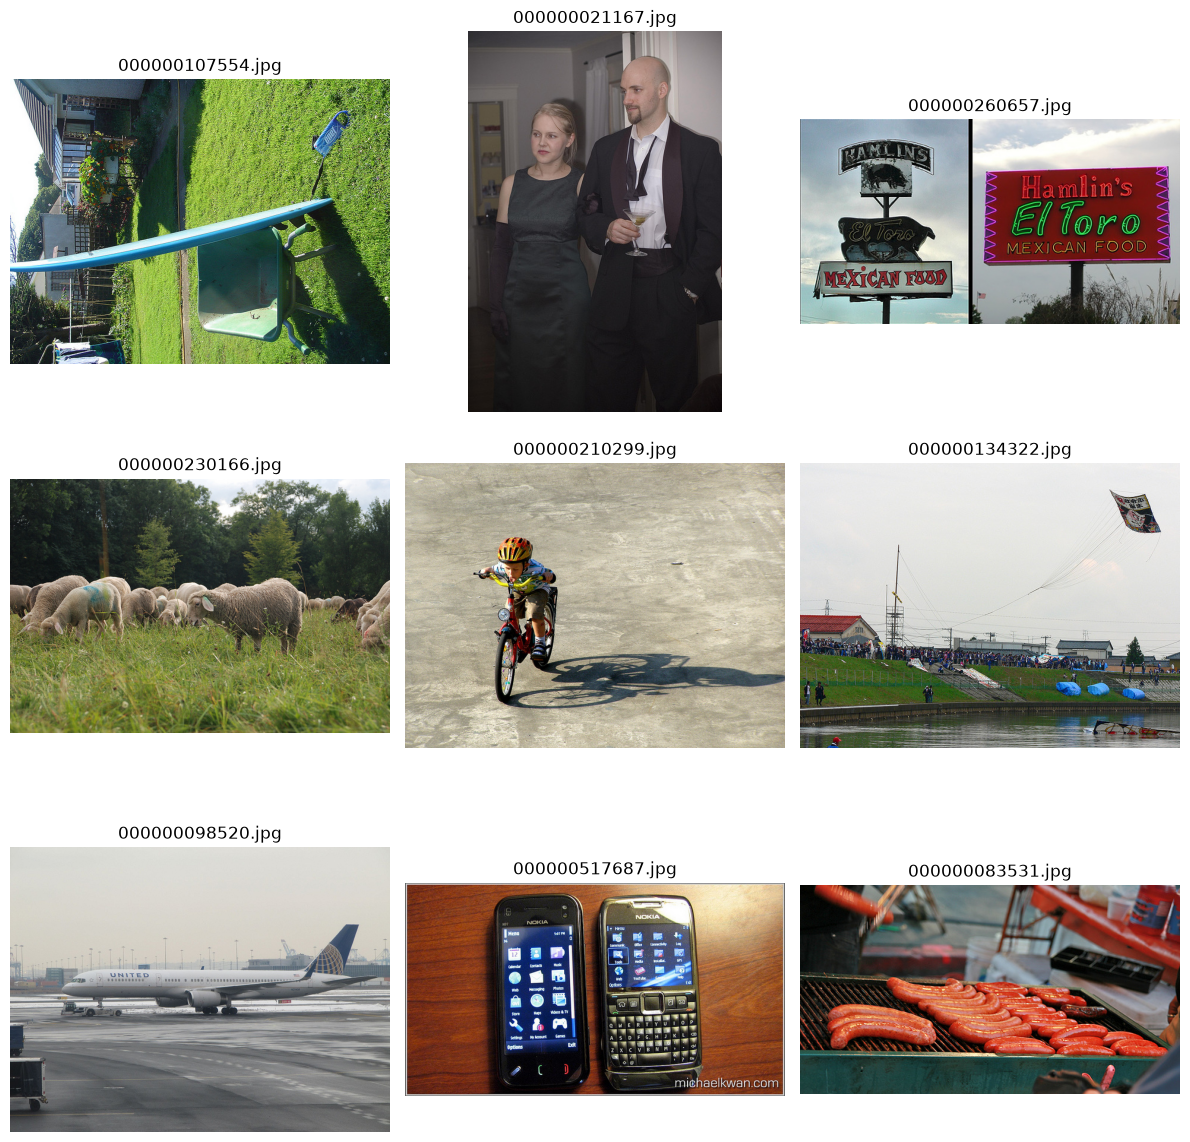

In [20]:
coco_images = list(COCO_EXTRACT_DIR.glob("*.jpg"))

random.seed(42)

sample_images = random.sample(
    coco_images,
    9
)

plt.figure(figsize=(12, 12))

for i, image_path in enumerate(sample_images):

    image = Image.open(image_path)

    plt.subplot(3, 3, i + 1)
    plt.imshow(image)
    plt.title(image_path.name)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [21]:
random.seed(42)

NUM_COCO_TEST_IMAGES = 500

coco_test_images = random.sample(
    coco_images,
    NUM_COCO_TEST_IMAGES
)

print(
    "Selected",
    len(coco_test_images),
    "COCO images for initial experiment."
)

Selected 500 COCO images for initial experiment.


In [22]:
import requests

COCO_ANNOTATION_URL = (
    "http://images.cocodataset.org/annotations/"
    "annotations_trainval2017.zip"
)

COCO_ANNOTATION_ZIP = (
    COCO_DIR / "annotations_trainval2017.zip"
)

if not COCO_ANNOTATION_ZIP.exists():

    print("Downloading COCO annotations...")

    response = requests.get(
        COCO_ANNOTATION_URL,
        stream=True
    )

    response.raise_for_status()

    with open(COCO_ANNOTATION_ZIP, "wb") as f:

        for chunk in response.iter_content(
            chunk_size=1024 * 1024
        ):
            if chunk:
                f.write(chunk)

    print("Download complete.")

else:
    print("Annotations already downloaded.")

Annotations already downloaded.


In [23]:
COCO_ANNOTATIONS_DIR = COCO_DIR / "annotations"

if not COCO_ANNOTATIONS_DIR.exists():

    with zipfile.ZipFile(
        COCO_ANNOTATION_ZIP,
        "r"
    ) as zip_ref:

        zip_ref.extractall(COCO_DIR)

    print("Annotations extracted.")

else:
    print("Annotations already extracted.")

Annotations already extracted.


In [24]:
COCO_PERSON_ID = 1

print("COCO person class ID:", COCO_PERSON_ID)

COCO person class ID: 1


In [25]:
!pip install -q pycocotools

In [26]:
from pycocotools.coco import COCO

In [27]:
annotation_file = (
    COCO_ANNOTATIONS_DIR /
    "instances_val2017.json"
)

coco = COCO(str(annotation_file))

person_category_ids = coco.getCatIds(
    catNms=["person"]
)

print(person_category_ids)

loading annotations into memory...
Done (t=0.55s)
creating index...
index created!
[1]


In [28]:
person_image_ids = coco.getImgIds(
    catIds=person_category_ids
)

print(
    "Images containing people:",
    len(person_image_ids)
)

Images containing people: 2693


In [29]:
person_images = []

for image_id in person_image_ids:

    image_info = coco.loadImgs(image_id)[0]

    image_path = (
        COCO_EXTRACT_DIR /
        image_info["file_name"]
    )

    if image_path.exists():
        person_images.append(image_path)

print(
    "Available person images:",
    len(person_images)
)

Available person images: 2693


In [30]:
random.seed(42)

NUM_PERSON_IMAGES = 500

detection_test_images = random.sample(
    person_images,
    min(NUM_PERSON_IMAGES, len(person_images))
)

print(
    "Detection test images:",
    len(detection_test_images)
)

Detection test images: 500


In [7]:
import sys

project_path = r"C:\Users\akars\Capstone\AI_Intruder_Capstone"

if project_path in sys.path:
    sys.path.remove(project_path)

# Also remove the incorrectly loaded module if it exists
sys.modules.pop("datasets", None)

from datasets import load_dataset

print("Success!")
print(load_dataset)



C:\Users\akars\Capstone\test\YOLO11\myvenv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Success!
<function load_dataset at 0x000001E622BD4040>


In [8]:
from datasets import load_dataset

In [10]:
from huggingface_hub import snapshot_download

path = snapshot_download(
    repo_id="CUHK-CSE/wider_face",
    repo_type="dataset"
)

print(path)


Fetching 7 files:   0%|          | 0/7 [00:00<?, ?it/s]C:\Users\akars\Capstone\test\YOLO11\myvenv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\akars\.cache\huggingface\hub. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
Fetching 7 files: 100%|██████████| 7/7 [53:01<00:00, 454.57s/it]

C:\Users\akars\.cache\huggingface\hub\datasets--CUHK-CSE--wider_face\snapshots\db171f1b7fedf4d3453e81297ff02f9915356d19


In [13]:
import os

for root, dirs, files in os.walk(path):
    level = root.replace(path, "").count(os.sep)
    indent = "  " * level
    print(f"{indent}{os.path.basename(root)}/")

    for file in files[:10]:
        print(f"{indent}  {file}")

db171f1b7fedf4d3453e81297ff02f9915356d19/
  .gitattributes
  README.md
  wider_face.py
  data/
    wider_face_split.zip
    WIDER_test.zip
    WIDER_train.zip
    WIDER_val.zip


In [14]:
import os

for root, dirs, files in os.walk(path):
    print(root)
    for f in files[:10]:
        print("   ", f)

C:\Users\akars\.cache\huggingface\hub\datasets--CUHK-CSE--wider_face\snapshots\db171f1b7fedf4d3453e81297ff02f9915356d19
    .gitattributes
    README.md
    wider_face.py
C:\Users\akars\.cache\huggingface\hub\datasets--CUHK-CSE--wider_face\snapshots\db171f1b7fedf4d3453e81297ff02f9915356d19\data
    wider_face_split.zip
    WIDER_test.zip
    WIDER_train.zip
    WIDER_val.zip


In [20]:
import os
import zipfile

data_path = os.path.join(path, "data")
val_zip = os.path.join(data_path, "WIDER_val.zip")

extract_path = os.path.join(data_path, "WIDER_val")

with zipfile.ZipFile(val_zip, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Extracted to:", extract_path)


Extracted to: C:\Users\akars\.cache\huggingface\hub\datasets--CUHK-CSE--wider_face\snapshots\db171f1b7fedf4d3453e81297ff02f9915356d19\data\WIDER_val


In [21]:
from datasets import Dataset, Features, Image, Value

# Find image files
image_files = []

for root, dirs, files in os.walk(path):
    for file in files:
        if file.lower().endswith((".jpg", ".jpeg", ".png")):
            image_files.append(os.path.join(root, file))

print("Number of images:", len(image_files))

wider = Dataset.from_dict({
    "image": image_files
})

wider = wider.cast_column("image", Image())

print(wider)
print(wider.features)


Number of images: 3226
Dataset({
    features: ['image'],
    num_rows: 3226
})
{'image': Image(mode=None, decode=True)}


In [22]:
image_files = []

for root, dirs, files in os.walk(extract_path):
    for file in files:
        if file.lower().endswith((".jpg", ".jpeg", ".png")):
            image_files.append(os.path.join(root, file))

print("Number of validation images:", len(image_files))
print(image_files[:5])


Number of validation images: 3226
['C:\\Users\\akars\\.cache\\huggingface\\hub\\datasets--CUHK-CSE--wider_face\\snapshots\\db171f1b7fedf4d3453e81297ff02f9915356d19\\data\\WIDER_val\\WIDER_val\\images\\0--Parade\\0_Parade_marchingband_1_1004.jpg', 'C:\\Users\\akars\\.cache\\huggingface\\hub\\datasets--CUHK-CSE--wider_face\\snapshots\\db171f1b7fedf4d3453e81297ff02f9915356d19\\data\\WIDER_val\\WIDER_val\\images\\0--Parade\\0_Parade_marchingband_1_104.jpg', 'C:\\Users\\akars\\.cache\\huggingface\\hub\\datasets--CUHK-CSE--wider_face\\snapshots\\db171f1b7fedf4d3453e81297ff02f9915356d19\\data\\WIDER_val\\WIDER_val\\images\\0--Parade\\0_Parade_marchingband_1_1045.jpg', 'C:\\Users\\akars\\.cache\\huggingface\\hub\\datasets--CUHK-CSE--wider_face\\snapshots\\db171f1b7fedf4d3453e81297ff02f9915356d19\\data\\WIDER_val\\WIDER_val\\images\\0--Parade\\0_Parade_marchingband_1_139.jpg', 'C:\\Users\\akars\\.cache\\huggingface\\hub\\datasets--CUHK-CSE--wider_face\\snapshots\\db171f1b7fedf4d3453e81297ff02f9

In [23]:
from datasets import Dataset, Image

wider = Dataset.from_dict({
    "image": image_files
})

wider = wider.cast_column("image", Image())

print(wider)
print(wider.features)


Dataset({
    features: ['image'],
    num_rows: 3226
})
{'image': Image(mode=None, decode=True)}


In [19]:
print("Snapshot path:", path)

Snapshot path: C:\Users\akars\.cache\huggingface\hub\datasets--CUHK-CSE--wider_face\snapshots\db171f1b7fedf4d3453e81297ff02f9915356d19


In [24]:
sample = wider[0]

print(sample.keys())


dict_keys(['image'])


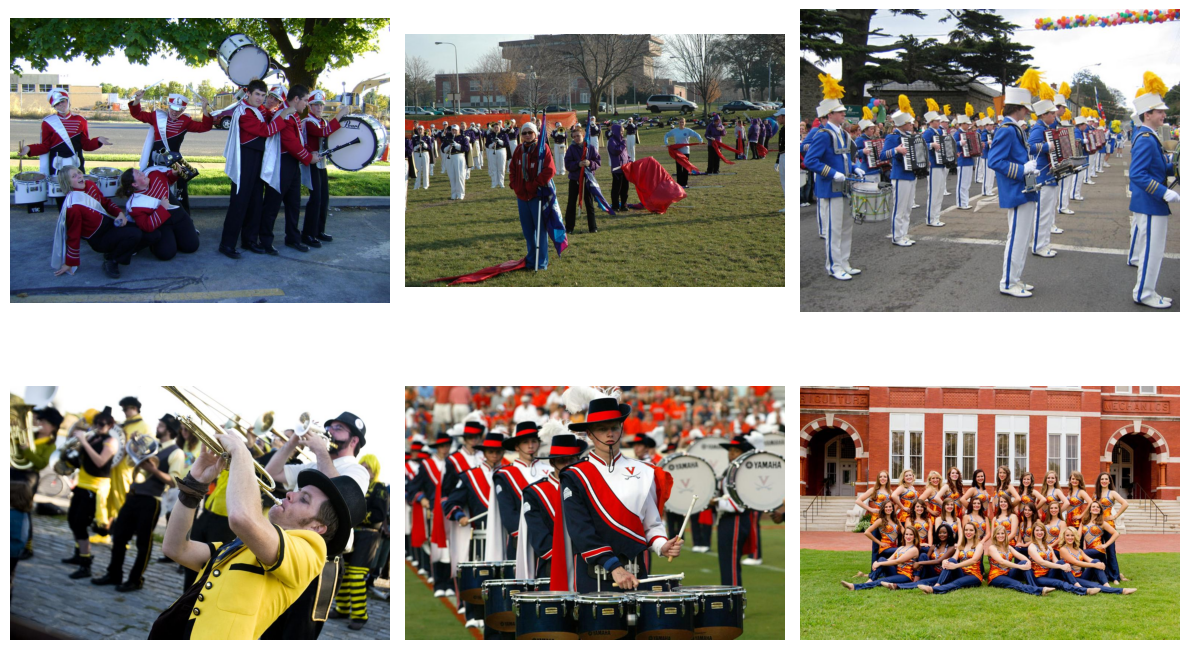

In [26]:
import matplotlib.pyplot as plt 
plt.figure(figsize=(12, 8))

for i in range(6):

    sample = wider[i]

    image = sample["image"]

    plt.subplot(2, 3, i + 1)

    plt.imshow(image)
    plt.axis("off")

plt.tight_layout()
plt.show()


In [29]:
import pandas as pd
dataset_summary = pd.DataFrame({
    "Dataset": [
        "LFW",
        "COCO 2017 Validation",
        "WIDER FACE Validation"
    ],
    "Purpose": [
        "Face recognition",
        "Person detection",
        "Face detection"
    ],
    "Status": [
        "Downloaded",
        "Downloaded",
        "Loaded"
    ]
})

dataset_summary

,Dataset,Purpose,Status
0,LFW,Face recognition,Downloaded
1,COCO 2017 Validation,Person detection,Downloaded
2,WIDER FACE Validation,Face detection,Loaded
